# Eksperimen 5: Model Final XGBoost + BiLSTM

Model terpilih untuk paper: **XGBoost + BiLSTM**. Plot fit pada NO2 h1.

In [1]:
import sys
BASE='/home/mada/Documents/Kuliah/Algorithms and Complexity/02_Kode/hybrid-lgbm-xgb'
sys.path.insert(0,BASE)
import hybrid as H
import numpy as np, pandas as pd
from scipy.stats import boxcox
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

window=120; test_len=720; poll='NO2'; hz=1
df=H.load()
s_bc,_=boxcox(df[poll].clip(lower=1e-3))
train,test=s_bc[:-test_len],s_bc[-test_len:]
X=H.make_features(pd.Series(s_bc,index=df.index))
f=H.fit_gbm('xgboost',X.iloc[:-test_len],train,X.iloc[-test_len:])
resid_train=np.asarray(train)[-len(f):]-f
resid_test=np.asarray(test)[-len(f):]-f
fc_w=f[:window]; re_w=resid_test[:window]; test_w=test[:window]
sc=MinMaxScaler(); sc.fit(resid_train.reshape(-1,1))
rt=sc.transform(resid_train.reshape(-1,1)).flatten()
rs=sc.transform(re_w.reshape(-1,1)).flatten()
pr,_=H.stage2_bilstm(rt,rs,hz,60)
pr=sc.inverse_transform(np.asarray(pr).reshape(-1,1)).flatten()
n=min(len(pr),len(re_w))
final=fc_w[:n]+pr[:n]; actual=test_w[:n]
rmse=np.sqrt(mean_squared_error(actual,final))
print(f'RMSE NO2 h1 (window 120) = {rmse:.4f}')

I0000 00:00:1793385671.561666 1484429 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


/home/mada/Documents/Kuliah/Algorithms and Complexity/02_Kode/refenv/lib/python3.14/site-packages/keras/src/layers/rnn/bidirectional.py:110: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


RMSE NO2 h1 (window 120) = 0.9241


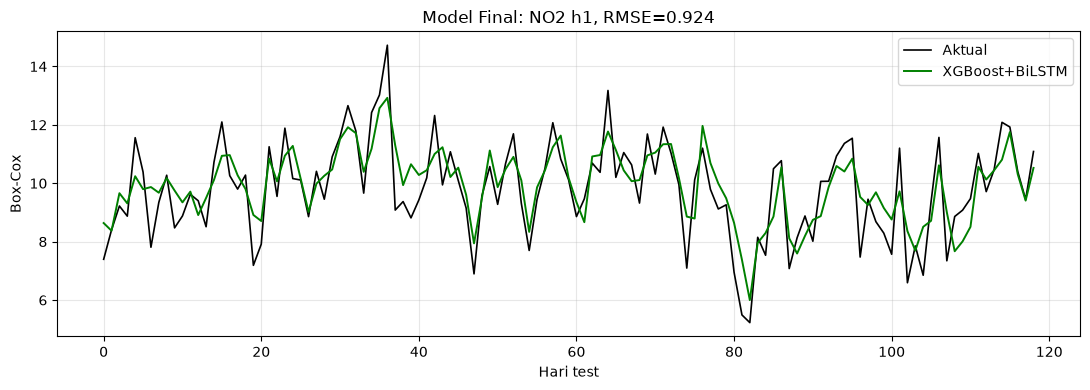

In [2]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(actual,label='Aktual',color='black',lw=1.2)
ax.plot(final,label='XGBoost+BiLSTM',color='green',lw=1.4)
ax.set_title(f'Model Final: NO2 h1, RMSE={rmse:.3f}')
ax.set_xlabel('Hari test'); ax.set_ylabel('Box-Cox'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()